# EDA development: Bệnh tim Cleveland
Chỉ dùng development để tìm hiểu dữ liệu. Không chọn feature/model bằng test.

In [1]:
from pathlib import Path
import sys
root = Path.cwd()
if not (root / "src").exists(): root = root.parent
sys.path.insert(0, str(root / "src"))
import pandas as pd, numpy as np
from IPython.display import display, Image, Markdown
from healthcare_ml.data import load_dataset, feature_columns


In [2]:
df, split = load_dataset("heart")
dev = df.iloc[split["development"]]
display(dev[feature_columns(df,"heart")].head())
display(dev.y.value_counts().rename("count"))
display(dev[feature_columns(df,"heart")].isna().mean().sort_values(ascending=False).head(15))

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0
5,56.0,1.0,2.0,120.0,236.0,0.0,0.0,178.0,0.0,0.8,1.0,0.0,3.0


y
0    131
1    111
Name: count, dtype: int64

ca          0.004132
thal        0.004132
age         0.000000
sex         0.000000
cp          0.000000
trestbps    0.000000
chol        0.000000
fbs         0.000000
restecg     0.000000
thalach     0.000000
exang       0.000000
oldpeak     0.000000
slope       0.000000
dtype: float64

## Phân phối, missingness và các câu hỏi
So sánh theo nhãn chỉ là liên hệ thống kê. Giữ `None` xét nghiệm như một trạng thái; mọi imputer/encoder học riêng trong train-fold.

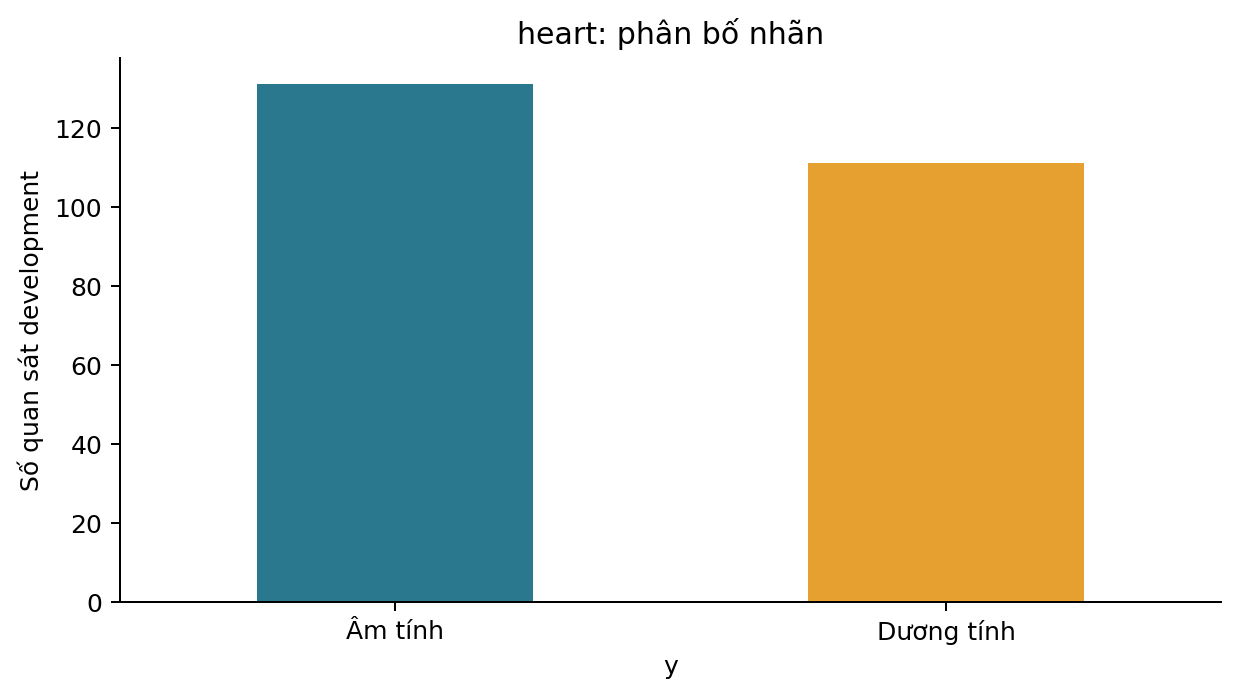

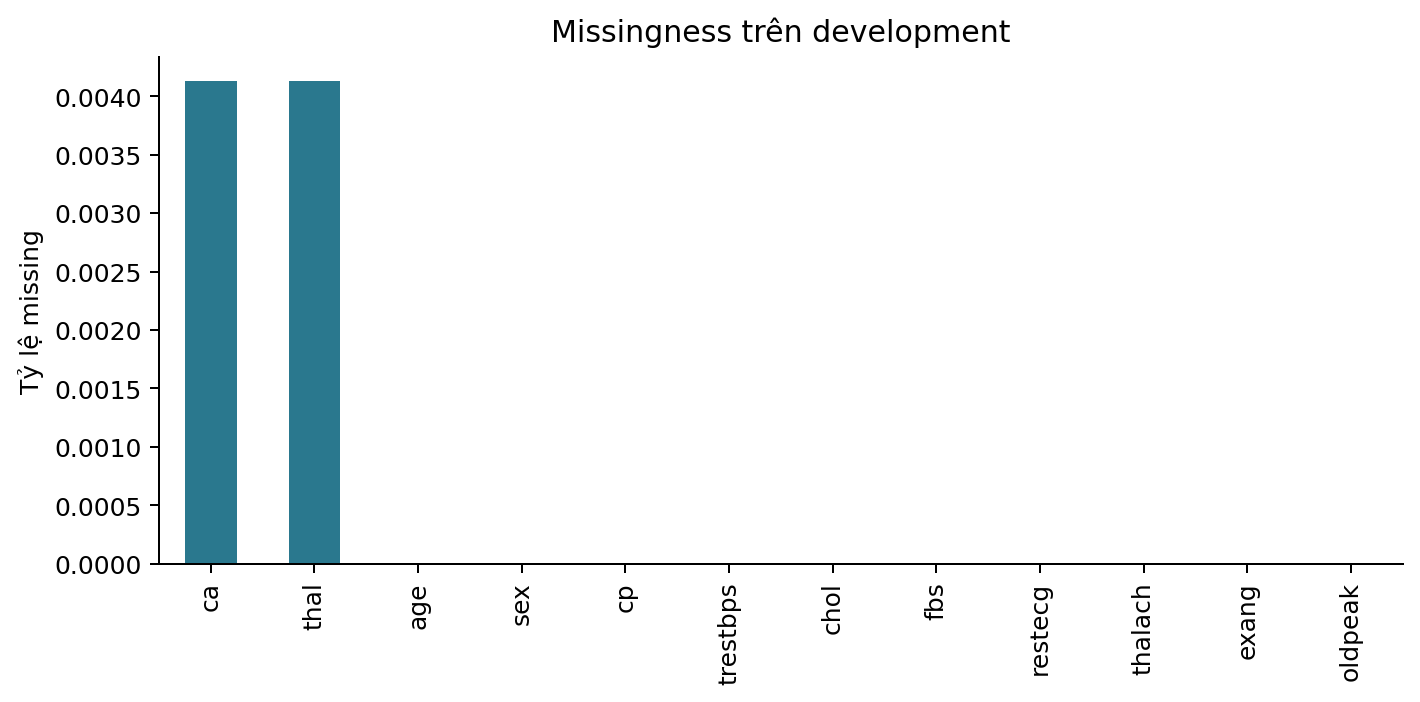

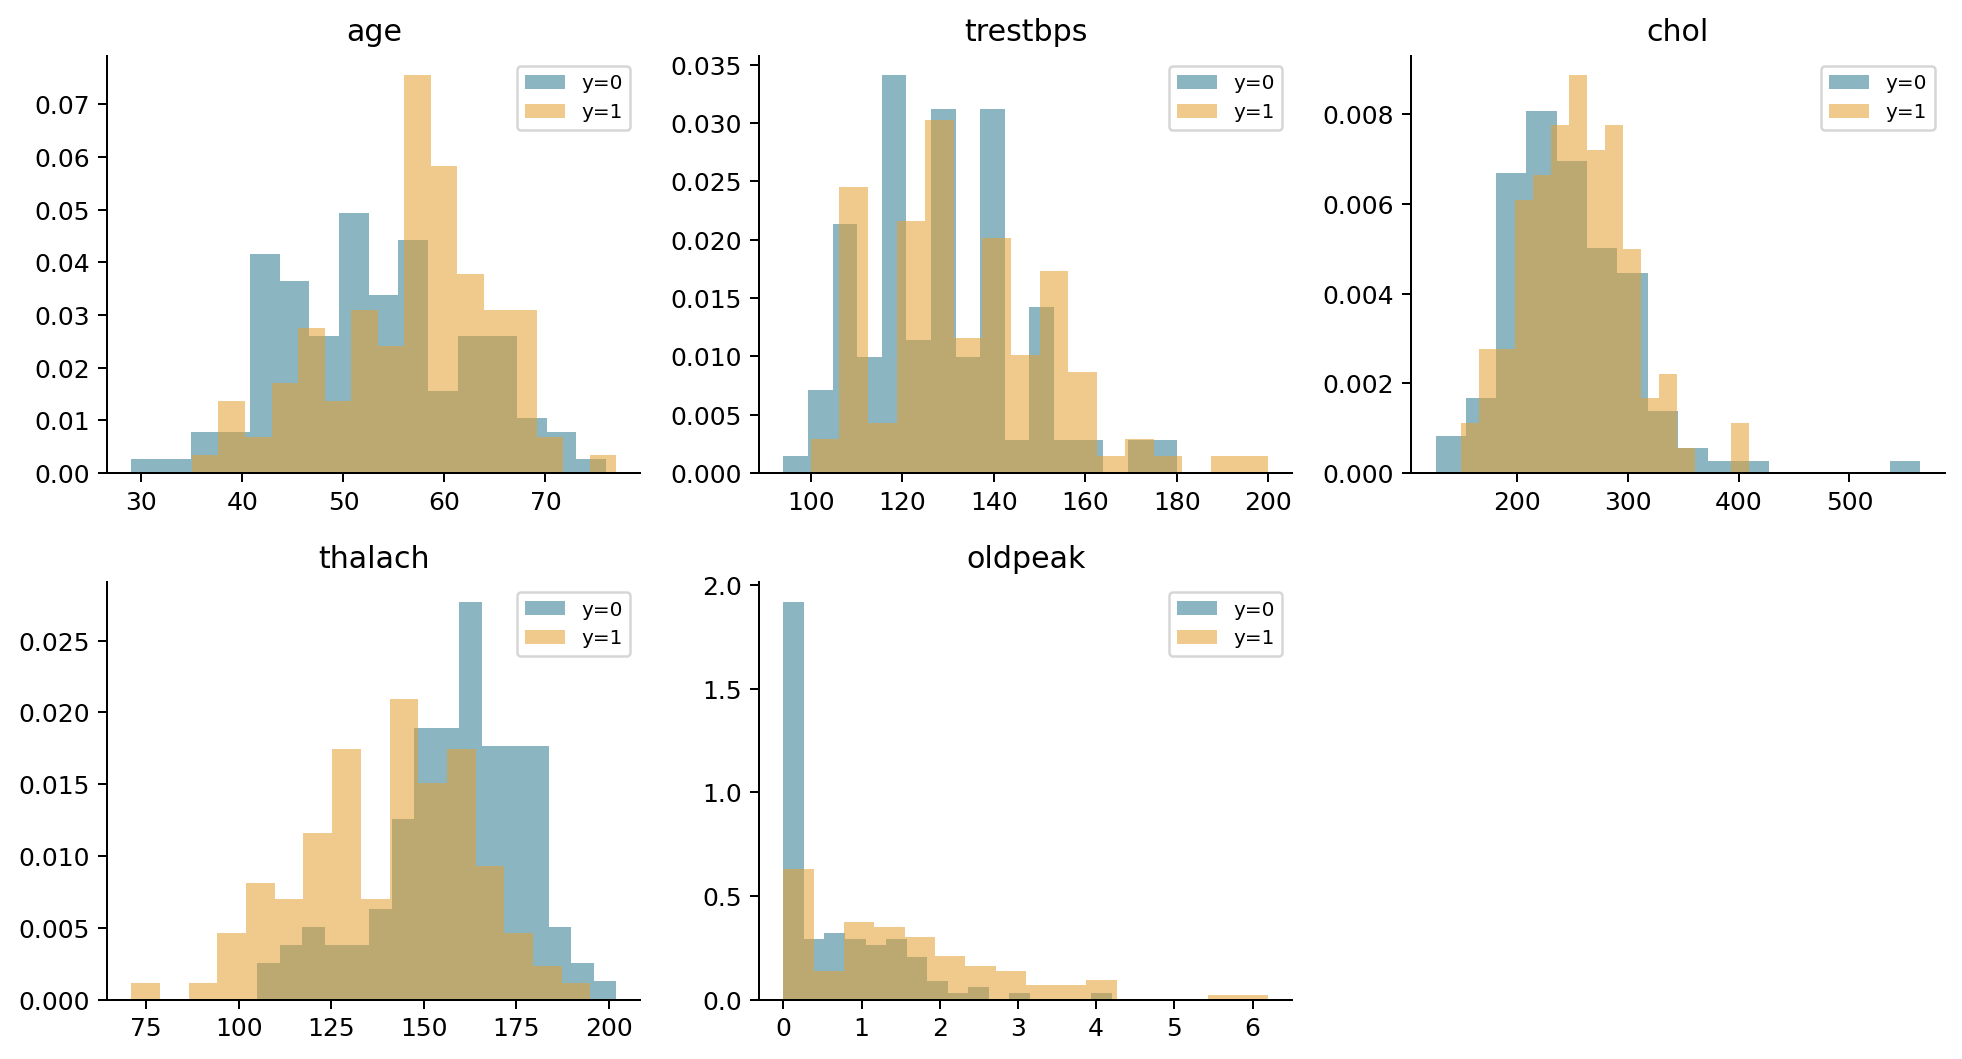

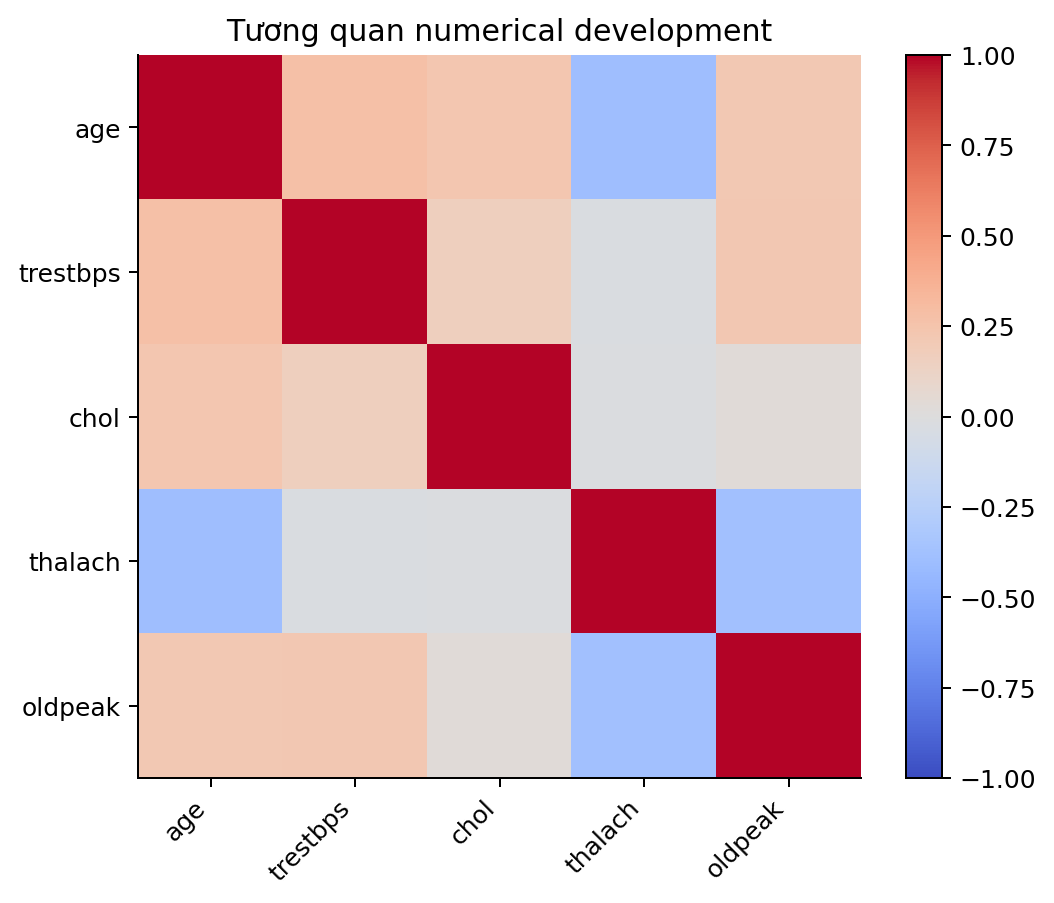

In [3]:
for suffix in ["labels", "missing", "distributions", "correlation"]:
    display(Image(filename=str(root / "artifacts/figures" / f"heart_{suffix}.png")))

## Split kiểm toán
Tập test giữ riêng; group patient tách biệt. Fit, calibration, threshold và test không giao nhau.

In [4]:
parts = ["fit", "calibration", "threshold", "test"]
for i,a in enumerate(parts):
    for b in parts[i+1:]:
        assert not set(df.iloc[split[a]].patient_nbr) & set(df.iloc[split[b]].patient_nbr)
print("Verified disjoint groups", {k:len(split[k]) for k in parts})

Verified disjoint groups {'fit': 169, 'calibration': 36, 'threshold': 37, 'test': 61}
